# Step by step on the synthetic network

This notebook applies each function of `stormwater_qc` in turn to the
synthetic network and draws the result, so that every correction can be
checked by eye. The synthetic network is a street grid with the defect types
commonly found in municipal infrastructure data; the generator records
which pipes and inlets it altered (`net.truth`), so each figure also states
whether the correction matches the ground truth.

The same chain is run in one call by `stormwater_qc.workflow.run_workflow`.

In [1]:
import sys, tempfile
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # run from examples/ without installing

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

from stormwater_qc import geometry, networks, topology, inlets, diameters, slopes, swmm
from stormwater_qc.synthetic import make_synthetic_network, summary

import warnings
warnings.filterwarnings("ignore", module="pysheds")

# reference palette: categorical slots in fixed order, one-hue sequential ramp
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
INK, MUTED, GRID, SURFACE = "#1f1f1e", "#8a897f", "#d9d8d2", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": GRID, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9,
                     "axes.titlelocation": "left", "axes.titlesize": 10})


def frame(ax, title=None, center=None, half=None):
    """Map axes: equal aspect, no ticks, optional zoom on center +- half (m)."""
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    if center is not None:
        ax.set_xlim(center[0] - half, center[0] + half)
        ax.set_ylim(center[1] - half, center[1] + half)
        ax.add_artist(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, fill=False,
                                    edgecolor=GRID, linewidth=1))
    if title:
        ax.set_title(title)


def vertices(ax, gdf, **kw):
    """Draw the vertices of line features."""
    xy = np.vstack([np.asarray(g.coords)[:, :2] for g in gdf.geometry])
    ax.plot(xy[:, 0], xy[:, 1], linestyle="", **kw)


def legend(ax, items, ncol=2):
    """Legend below the axes, so it never covers the map."""
    ax.legend(handles=items, frameon=False, fontsize=8, ncol=ncol,
              loc="upper left", bbox_to_anchor=(0, -0.01))


def line(color, label, lw=2):
    return Line2D([], [], color=color, linewidth=lw, label=label)


def dot(color, label, marker="o"):
    return Line2D([], [], color=color, marker=marker, linestyle="", markersize=6, label=label)

## 0. Synthetic network and injected defects

In [2]:
net = make_synthetic_network(seed=0)
truth = net.truth
tmp = Path(tempfile.mkdtemp())
dem_fine = net.write_dem(str(tmp / "dem_1m.tif"))
dem_coarse = net.write_dem(str(tmp / "dem_5m.tif"), coarse=True)
print(f"{len(net.pipes)} pipes, {len(net.inlets)} inlets, {len(net.outfalls)} outfalls")
summary(net).to_frame()

118 pipes, 93 inlets, 2 outfalls


,injected
near_miss,35
mid_segment,3
isolated,16
disconnected,1
duplicate,4
reversed,15
zero_diameter,6
depth_as_diameter,2
displaced_inlet,23
remote_inlet,5


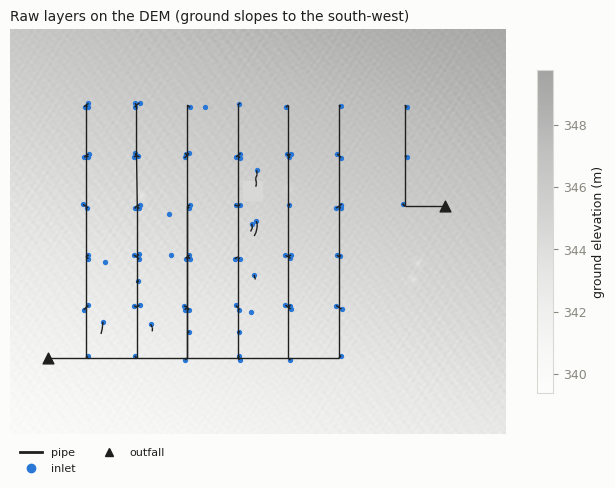

In [3]:
fig, ax = plt.subplots(figsize=(8, 7))
t = net.dem_transform
extent = [t.c, t.c + t.a * net.dem.shape[1], t.f + t.e * net.dem.shape[0], t.f]
im = ax.imshow(net.dem, extent=extent, cmap="Greys", alpha=0.35)
net.pipes.plot(ax=ax, color=INK, linewidth=1)
net.inlets.plot(ax=ax, color=CAT[0], markersize=8)
net.outfalls.plot(ax=ax, color=INK, marker="^", markersize=60)
frame(ax, "Raw layers on the DEM (ground slopes to the south-west)")
cb = fig.colorbar(im, ax=ax, shrink=0.6, label="ground elevation (m)")
legend(ax, [line(INK, "pipe"), dot(CAT[0], "inlet"), dot(INK, "outfall", "^")])
plt.show()

## 1. Geometry: snap near-miss ends, split into segments

`geometry.clean_geometry` moves pipe ends that are within 0.1 m of another
pipe's vertex onto that vertex, moves ends that are within 0.1 m of the
middle of a segment onto it (inserting a vertex there), and splits every
polyline into 2-vertex segments. The panels zoom on one near-miss joint
(a few centimetres wide) and on one connector meeting a trunk mid-segment.

{'snapped_to_vertex': 35, 'snapped_to_segment': 3, 'segments': 147}


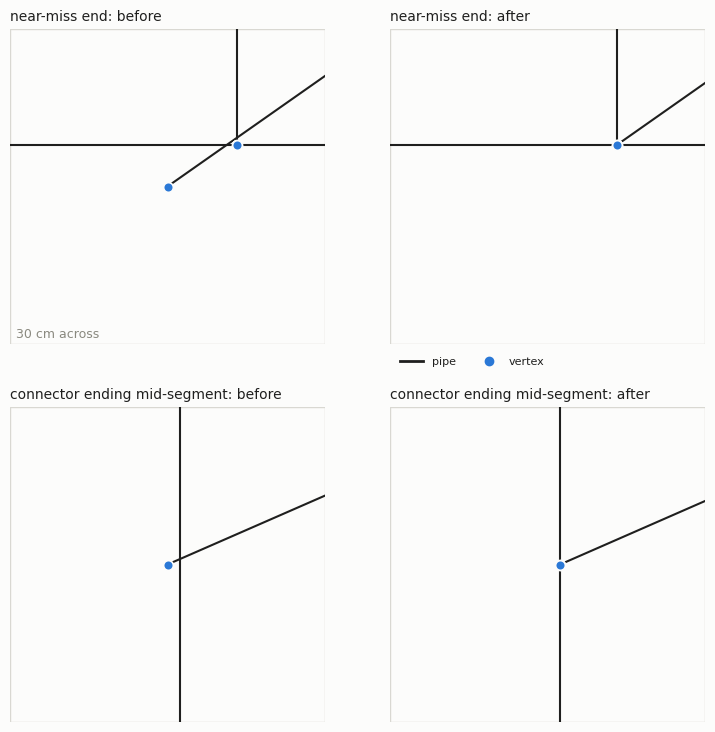

In [4]:
segments, report = geometry.clean_geometry(net.pipes, tolerance=0.1)
print(report)

near_id = sorted(truth["near_miss"] & set(net.pipes.pipe_id[net.pipes.diameter == 0.381]))[0]
near_end = net.pipes.set_index("pipe_id").geometry[near_id]
# the end of the connector that should touch the trunk (its downstream end, unless reversed)
near_xy = near_end.coords[0] if near_id in truth["reversed"] else near_end.coords[-1]
mid_id = sorted(truth["mid_segment"])[0]
mid_line = net.pipes.set_index("pipe_id").geometry[mid_id]
mid_xy = min(mid_line.coords, key=lambda c: net.pipes[net.pipes.pipe_id != mid_id].distance(
    gpd.points_from_xy([c[0]], [c[1]])[0]).min())

fig, axes = plt.subplots(2, 2, figsize=(9, 9))
for row, (xy, half, what) in enumerate([(near_xy, 0.15, "near-miss end"),
                                        (mid_xy, 0.15, "connector ending mid-segment")]):
    for col, (gdf, label) in enumerate([(net.pipes, "before"), (segments, "after")]):
        ax = axes[row, col]
        gdf.plot(ax=ax, color=INK, linewidth=1.5)
        vertices(ax, gdf, marker="o", markersize=7, color=CAT[0],
                 markeredgecolor=SURFACE, markeredgewidth=1.2)
        frame(ax, f"{what}: {label}", xy, half)
axes[0, 0].annotate("30 cm across", (0.02, 0.02), xycoords="axes fraction", color=MUTED)
legend(axes[0, 1], [line(INK, "pipe"), dot(CAT[0], "vertex")])
plt.show()

## 2. Close digitizing gaps

`networks.reconnect_networks` looks for networks that reach no outfall and
moves their closest dangling end onto a network that does, if the gap is at
most 5 m. Here the upper part of one trunk is cut off by a 3-m gap.
Colours identify the networks (identity only; order is arbitrary).

moves (segment_id, gap m): [(np.int64(7), 3.041)]
networks before: 9  after: 8


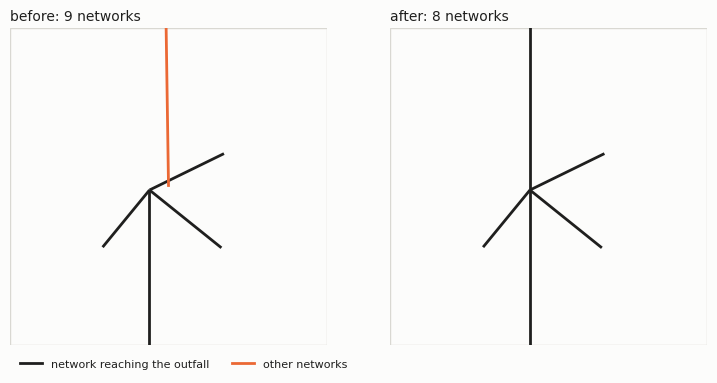

In [5]:
before_ids = networks.identify_networks(segments)
segments_rc, moves = networks.reconnect_networks(segments, net.outfalls, max_gap=5.0)
after_ids = networks.identify_networks(segments_rc)
print("moves (segment_id, gap m):", moves)
print("networks before:", before_ids.nunique(), " after:", after_ids.nunique())

gap_xy = net.pipes.set_index("pipe_id").geometry[sorted(truth["disconnected"])[0]].coords[-1]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
for ax, gdf, ids, label in [(axes[0], segments, before_ids, "before"),
                            (axes[1], segments_rc, after_ids, "after")]:
    main = ids.value_counts().index[0]
    gdf[ids == main].plot(ax=ax, color=INK, linewidth=2)
    gdf[ids != main].plot(ax=ax, color=CAT[1], linewidth=2)
    frame(ax, f"{label}: {ids.nunique()} networks", gap_xy, 25)
legend(axes[0], [line(INK, "network reaching the outfall"), line(CAT[1], "other networks")])
plt.show()

## 3. Remove networks that drain nowhere

`networks.classify_networks` summarises every network; `remove_isolated_networks`
keeps those reaching an outfall (or larger than 60 segments, or listed in
`keep_ids`) and removes the rest. Networks of 5-60 segments without an
outfall are flagged `inspect` for a visual check in GIS.

,n_segments,length,has_outfall,category
network_id,,,,
1,124,8717.792077,True,outfall
2,7,608.067990,True,outfall
3,2,32.598780,False,small
4,4,66.909127,False,small
5,2,30.118692,False,small
6,3,48.873644,False,small
7,1,18.848222,False,small
8,4,62.271579,False,small


removed 16 segments from 16 pipes; matches truth: True


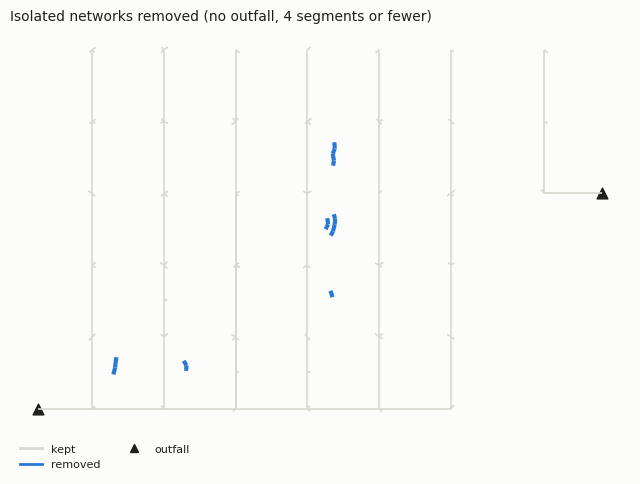

In [6]:
kept, removed, table = networks.remove_isolated_networks(segments_rc, net.outfalls)
display(table)
ok = set(removed.parent_id) == truth["isolated"]
print(f"removed {len(removed)} segments from {removed.parent_id.nunique()} pipes; matches truth: {ok}")

fig, ax = plt.subplots(figsize=(8, 7))
kept.plot(ax=ax, color=GRID, linewidth=1.2)
removed.plot(ax=ax, color=CAT[0], linewidth=3)
net.outfalls.plot(ax=ax, color=INK, marker="^", markersize=60)
frame(ax, "Isolated networks removed (no outfall, 4 segments or fewer)")
legend(ax, [line(GRID, "kept"), line(CAT[0], "removed"), dot(INK, "outfall", "^")])
plt.show()

## 4. Remove duplicate pipes

`networks.remove_duplicates` drops segments that share both end points with
an earlier segment, whichever direction they were digitized in.

removed 7 duplicate segments; matches truth: True


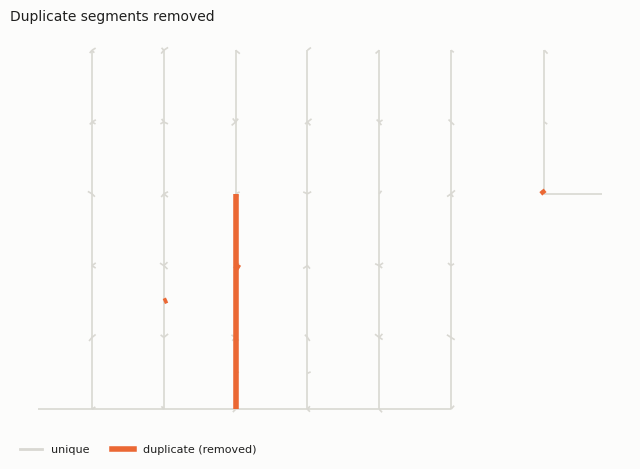

In [7]:
unique, dups = networks.remove_duplicates(kept)
ok = set(dups.parent_id) == truth["duplicate"]
print(f"removed {len(dups)} duplicate segments; matches truth: {ok}")

fig, ax = plt.subplots(figsize=(8, 7))
unique.plot(ax=ax, color=GRID, linewidth=1.2)
dups.plot(ax=ax, color=CAT[1], linewidth=4)
frame(ax, "Duplicate segments removed")
legend(ax, [line(GRID, "unique"), line(CAT[1], "duplicate (removed)", 4)])
plt.show()

## 5. Junctions and flow direction

`topology.build_nodes` creates a junction at every segment end and records
the upstream and downstream junction of each segment (as PCSWMM
Auto-Connect does, from the digitized direction). `orient_to_outfalls` then
computes the distance along the network from every junction to its outfall
and points each segment from its farther to its nearer end, which corrects
pipes digitized against the flow.

126 junctions; 17 segments reversed; matches truth: True


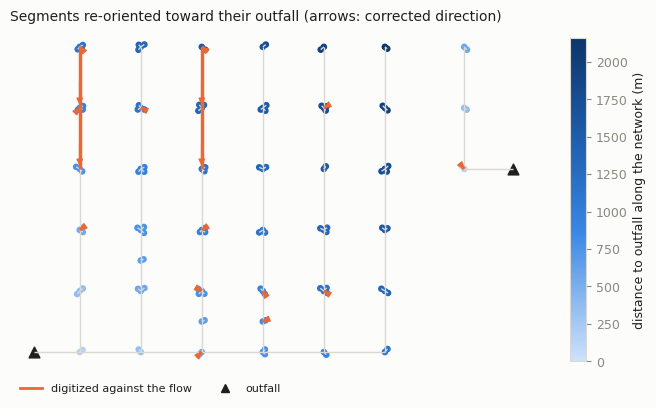

In [8]:
seg_nodes, junctions = topology.build_nodes(unique)
oriented, dist = topology.orient_to_outfalls(seg_nodes, junctions, net.outfalls)
flipped = set(oriented.loc[oriented.reversed, "parent_id"])
print(f"{len(junctions)} junctions; {oriented.reversed.sum()} segments reversed;"
      f" matches truth: {flipped == truth['reversed']}")

fig, ax = plt.subplots(figsize=(8.5, 7))
oriented.plot(ax=ax, color=GRID, linewidth=1)
oriented[oriented.reversed].plot(ax=ax, color=CAT[1], linewidth=2.5)
j = junctions.assign(dist=dist.values)
j.plot(ax=ax, column="dist", cmap=BLUES, markersize=14, legend=True,
       legend_kwds={"shrink": 0.6, "label": "distance to outfall along the network (m)"})
for g in oriented.geometry[oriented.parent_id.isin([p for p in flipped])][:40]:
    (x0, y0), (x1, y1) = g.coords
    ax.annotate("", (x1, y1), (x0 + 0.55 * (x1 - x0), y0 + 0.55 * (y1 - y0)),
                arrowprops=dict(arrowstyle="-|>", color=CAT[1], lw=1.2))
net.outfalls.plot(ax=ax, color=INK, marker="^", markersize=60)
frame(ax, "Segments re-oriented toward their outfall (arrows: corrected direction)")
legend(ax, [line(CAT[1], "digitized against the flow"), dot(INK, "outfall", "^")])
plt.show()

## 6. Inlets: keep those on a pipe, snap them to a junction

`inlets.select_inlets` keeps the inlets within 1 m of a retained pipe
(dropping remote inlets and those on removed fragments); `snap_inlets` moves
each inlet to its nearest junction and flags moves larger than 2 m for
review. The zoom shows a few inlets that were off the end of their
connector, with their displacement.

dropped 11 inlets; matches truth: True
snap distance: median 0.00 m, max 5.49 m; 17 to review


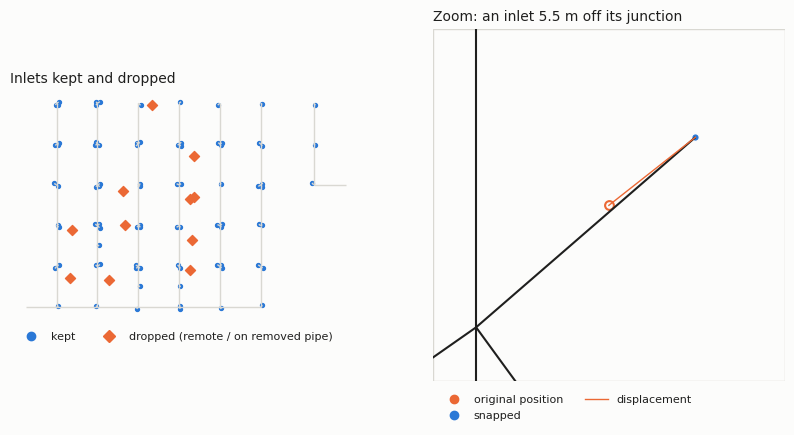

In [9]:
selected, dropped = inlets.select_inlets(net.inlets, oriented, distance=1.0)
snapped = inlets.snap_inlets(selected, junctions, review_distance=2.0)
expect = truth["remote_inlet"] | truth["isolated_inlets"]
print(f"dropped {len(dropped)} inlets; matches truth: {set(dropped.inlet_id) == expect}")
print(f"snap distance: median {snapped.snap_distance.median():.2f} m, "
      f"max {snapped.snap_distance.max():.2f} m; {snapped.needs_review.sum()} to review")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
ax = axes[0]
oriented.plot(ax=ax, color=GRID, linewidth=1)
selected.plot(ax=ax, color=CAT[0], markersize=8)
dropped.plot(ax=ax, color=CAT[1], marker="D", markersize=26)
frame(ax, "Inlets kept and dropped")
legend(ax, [dot(CAT[0], "kept"), dot(CAT[1], "dropped (remote / on removed pipe)", "D")])

ax = axes[1]
far = snapped.snap_distance.idxmax()            # the most displaced inlet
centre = selected.geometry.loc[far].coords[0]
half = max(6.0, 1.6 * snapped.snap_distance.max())
oriented.plot(ax=ax, color=INK, linewidth=1.5)
for a, b in zip(selected.geometry, snapped.geometry):
    ax.plot([a.x, b.x], [a.y, b.y], color=CAT[1], linewidth=1)
selected.plot(ax=ax, color=SURFACE, edgecolor=CAT[1], markersize=40, linewidth=1.5)
snapped.plot(ax=ax, color=CAT[0], markersize=30, edgecolor=SURFACE, linewidth=1)
frame(ax, f"Zoom: an inlet {snapped.snap_distance.max():.1f} m off its junction", centre, half)
legend(ax, [dot(CAT[1], "original position"), dot(CAT[0], "snapped"),
            line(CAT[1], "displacement", 1)])
plt.show()

## 7. Diameters: implausible and missing values

`diameters.flag_diameter_outliers` sets to missing any diameter more than
1.5 times the largest neighbouring diameter, or equal to the pipe's depth.
`reconstruct_diameters` then fills missing values from the upstream and
downstream pipes, or with the connector diameter (15 in) for pipes starting
at an inlet. Line width is proportional to diameter.

,parent_id,diameter,diameter_source,original,true
0,7,0.381,max_upstream,0.00,0.610
1,10,0.610,max_upstream,0.00,0.762
2,28,0.381,inlet_connector,3.55,0.381
3,65,0.381,inlet_connector,0.00,0.381
4,66,0.381,inlet_connector,0.00,0.381
5,75,0.381,inlet_connector,0.00,0.381
6,87,0.381,inlet_connector,0.00,0.381
7,91,0.381,inlet_connector,2.95,0.381


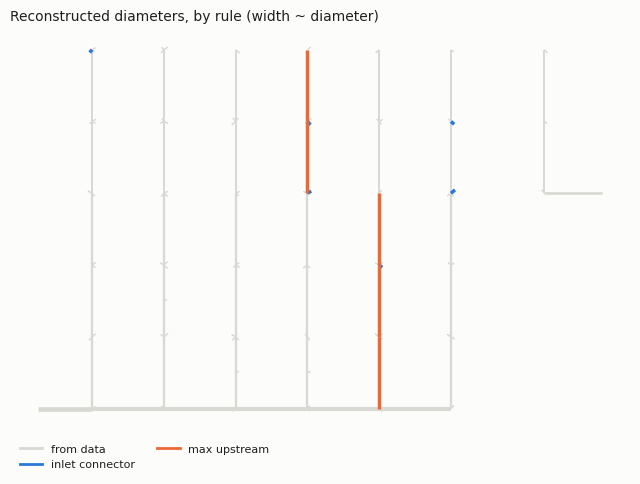

In [10]:
conn = topology.connectivity(oriented)
inlet_nodes = set(snapped.node_id)
flagged_seg, flagged = diameters.flag_diameter_outliers(oriented, conn, depth_field="depth")
filled = diameters.reconstruct_diameters(flagged_seg, inlet_nodes, connector_diameter=0.381)

fixed = filled[filled.diameter_source != "data"]
compare = fixed.drop_duplicates("parent_id")[["parent_id", "diameter", "diameter_source"]]
compare["original"] = compare.parent_id.map(net.pipes.set_index("pipe_id").diameter)
compare["true"] = compare.parent_id.map(truth["true_diameter"])
display(compare.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8, 7))
w = 0.4 + 3 * filled.diameter / filled.diameter.max()
filled.plot(ax=ax, color=GRID, linewidth=w)
colors = {"inlet_connector": CAT[0], "max_upstream": CAT[1], "common_up_down": CAT[2]}
for src, color in colors.items():
    sub = filled[filled.diameter_source == src]
    if len(sub):
        sub.plot(ax=ax, color=color, linewidth=np.maximum(2.5, 0.4 + 3 * sub.diameter / filled.diameter.max()))
frame(ax, "Reconstructed diameters, by rule (width ~ diameter)")
used = set(filled.diameter_source)
legend(ax, [line(GRID, "from data")] + [line(c, s.replace("_", " ")) for s, c in colors.items() if s in used])
plt.show()

## 8. Slopes within the velocity limits

`slopes.estimate_slopes` estimates each slope from the DEM (whole original
pipe first, then the coarse DEM, then segment by segment) and corrects the
segments whose full-flow velocity is outside 1.5-4.6 m/s from the velocities
of their neighbours. The histograms compare the velocities from the DEM
alone with the final ones; the map shows the final velocity.

slope_source
parent_fine_dem       53
connector_median      46
neighbour_velocity    14
segment_fine_dem       5
parent_coarse_dem      4
segment_coarse_dem     2
segment DEM slopes <= 0: 40 of 124


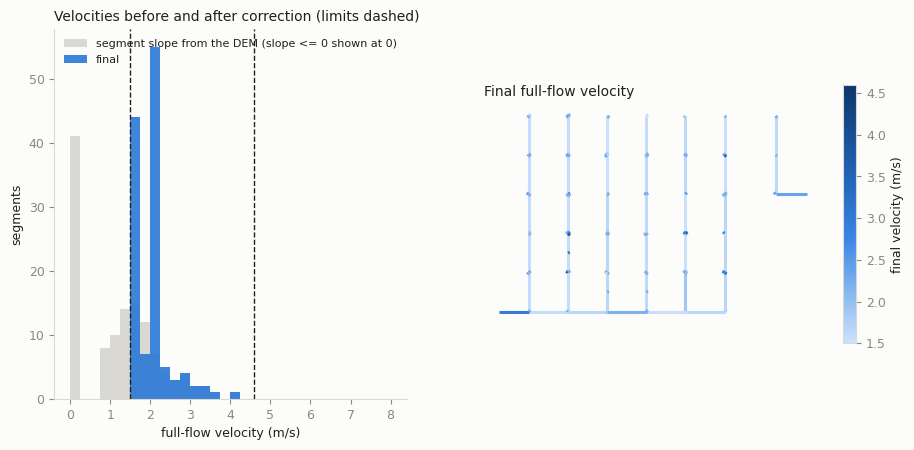

In [11]:
import rasterio
with rasterio.open(dem_fine) as src:
    dem, transform = src.read(1).astype(float), src.transform
with rasterio.open(dem_coarse) as src:
    demc, transformc = src.read(1).astype(float), src.transform

sloped = slopes.estimate_slopes(filled, junctions, dem, transform, demc, transformc,
                                inlet_nodes=inlet_nodes)
z = slopes.sample_dem(junctions, dem, transform)
raw_slope = (z.loc[sloped.us_node].to_numpy() - z.loc[sloped.ds_node].to_numpy()) / sloped.length
raw_v = slopes.full_flow_velocity(sloped.diameter, raw_slope)
print(sloped.slope_source.value_counts().to_string())
print(f"segment DEM slopes <= 0: {(raw_slope <= 0).sum()} of {len(sloped)}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
bins = np.linspace(0, 8, 33)
ax.hist(np.nan_to_num(raw_v, nan=0), bins=bins, color=GRID, label="segment slope from the DEM (slope <= 0 shown at 0)")
ax.hist(sloped.velocity, bins=bins, color=CAT[0], alpha=0.9, label="final")
for v in (1.5, 4.6):
    ax.axvline(v, color=INK, linewidth=1, linestyle="--")
ax.set_xlabel("full-flow velocity (m/s)"); ax.set_ylabel("segments")
ax.set_title("Velocities before and after correction (limits dashed)")
ax.legend(frameon=False, fontsize=8)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)

ax = axes[1]
sloped.plot(ax=ax, column="velocity", cmap=BLUES, linewidth=2.2, vmin=1.5, vmax=4.6,
            legend=True, legend_kwds={"shrink": 0.7, "label": "final velocity (m/s)"})
frame(ax, "Final full-flow velocity")
plt.show()

## 9. Inlet clusters and catch basins

`inlets.cluster_inlets` groups inlets within 25 m of each other (DBSCAN);
`cluster_points` gives one point per cluster; `watersheds.delineate`
(requires `pysheds`) delineates one catch basin per cluster point on the
5-m DEM.

82 inlets in 44 clusters (24 with more than one inlet)
pysheds not installed: basins skipped


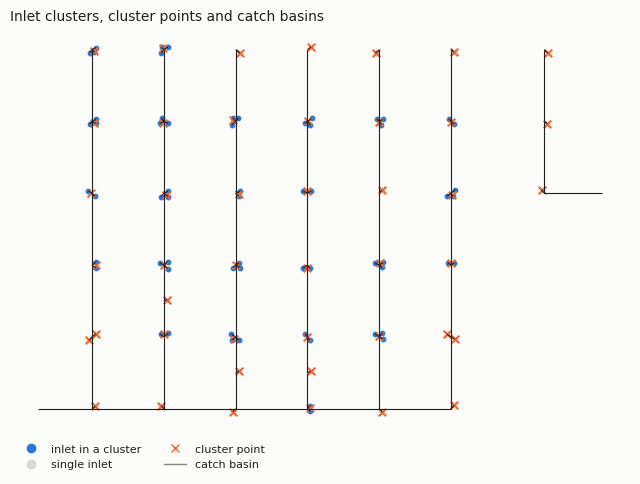

In [12]:
clustered = inlets.cluster_inlets(snapped, eps=25.0)
points = inlets.cluster_points(clustered)
print(f"{len(clustered)} inlets in {len(points)} clusters "
      f"({(clustered.cluster_id.value_counts() > 1).sum()} with more than one inlet)")
try:
    from stormwater_qc import watersheds
    basins = watersheds.delineate(dem_coarse, points, snap_distance=30.0)
    print(f"{len(basins)} catch basins, {basins.area.sum() / 1e6:.2f} km2")
except ImportError:
    basins = None
    print("pysheds not installed: basins skipped")

fig, ax = plt.subplots(figsize=(8, 7))
if basins is not None:
    basins.plot(ax=ax, color=SURFACE, edgecolor=MUTED, linewidth=0.6)
sloped.plot(ax=ax, color=INK, linewidth=0.8)
multi = clustered.cluster_id.map(clustered.cluster_id.value_counts()) > 1
clustered[~multi].plot(ax=ax, color=GRID, markersize=10)
clustered[multi].plot(ax=ax, color=CAT[0], markersize=10)
points.plot(ax=ax, color=CAT[1], marker="x", markersize=30)
frame(ax, "Inlet clusters, cluster points and catch basins")
legend(ax, [dot(CAT[0], "inlet in a cluster"), dot(GRID, "single inlet"),
            dot(CAT[1], "cluster point", "x"), line(MUTED, "catch basin", 1)])
plt.show()

## 10. One inlet per basin; merge connector capacity

`inlets.representative_inlets` keeps one inlet per cluster (the only one
inside its basin, or the one farthest from the basin centroid);
`merge_connectors` removes the connector pipes of the other inlets and
enlarges the kept connector so that its full-flow capacity equals the sum of
the removed ones. The zoom shows one cluster.

role
representative    44
removed           38
connector diameters before: [0.381, 0.381, 0.381]  after: [0.559]


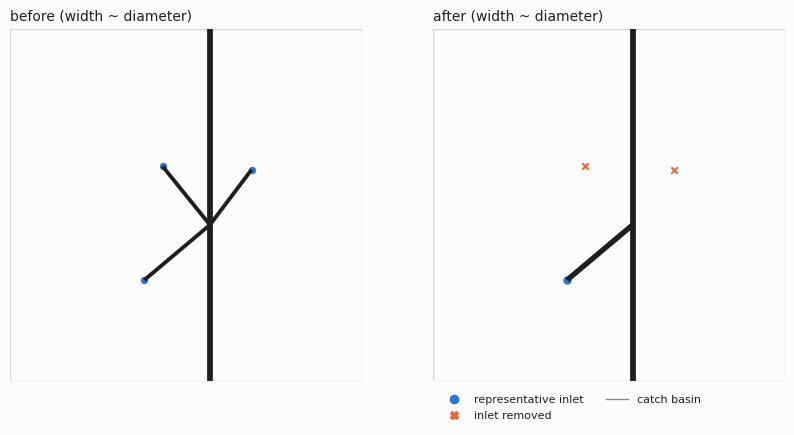

In [13]:
rep = inlets.representative_inlets(clustered, basins)
merged, roles = inlets.merge_connectors(sloped, rep)
print(roles.role.value_counts().to_string())

cid = roles[roles.role == "removed"].cluster_id.value_counts().index[0]
grp = roles[roles.cluster_id == cid]
centre = grp.union_all().centroid.coords[0]
kept_conn = merged[merged.us_node.isin(grp[grp.representative].node_id)]
before_conn = sloped[sloped.us_node.isin(grp.node_id)]
print("connector diameters before:", before_conn.diameter.round(3).tolist(),
      " after:", kept_conn.diameter.round(3).tolist())

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, gdf, label in [(axes[0], sloped, "before"), (axes[1], merged, "after")]:
    if basins is not None:
        basins[basins.gridcode == cid].plot(ax=ax, color=SURFACE, edgecolor=MUTED, linewidth=1)
    gdf.plot(ax=ax, color=INK, linewidth=0.5 + 6 * gdf.diameter)
    frame(ax, f"{label} (width ~ diameter)", centre, 30)
for role, color, marker in [("representative", CAT[0], "o"), ("removed", CAT[1], "X"),
                            ("kept_for_connectivity", CAT[2], "s")]:
    sub = roles[(roles.cluster_id == cid) & (roles.role == role)]
    if len(sub):
        sub.plot(ax=axes[1], color=color, marker=marker, markersize=50, edgecolor=SURFACE)
grp.plot(ax=axes[0], color=CAT[0], markersize=40, edgecolor=SURFACE)
legend(axes[1], [dot(CAT[0], "representative inlet"), dot(CAT[1], "inlet removed", "X"),
                 line(MUTED, "catch basin", 1)])
plt.show()

## 11. Junction depths, inverts and conduit offsets

`swmm.node_depths` gives each junction 36 in of cover plus the largest
connected diameter; `node_inverts` subtracts it from the ground; and
`conduit_offsets` computes the inlet or outlet offset that makes SWMM
reproduce each estimated slope. The profile follows one trunk from its top
to the outfall.

largest difference between SWMM slope and estimated slope: 2.7e-15


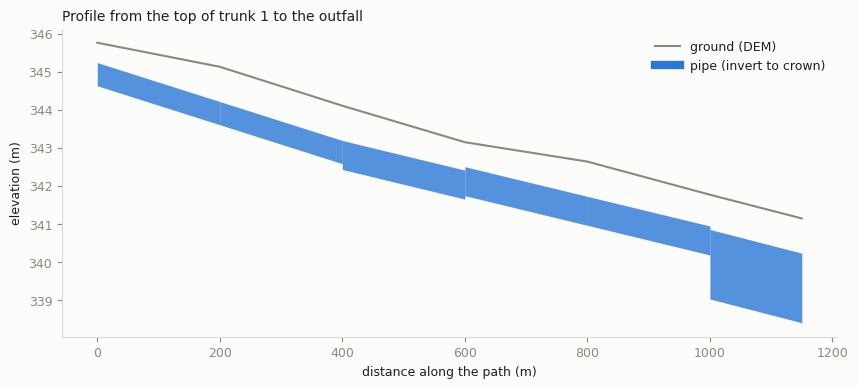

In [14]:
jn = swmm.drop_orphan_junctions(junctions, merged)
jn = swmm.node_depths(merged, jn)
jn = swmm.node_inverts(jn, dem, transform)
final = swmm.conduit_offsets(merged, jn)
err = np.abs(swmm.swmm_slope(final, jn) - final.slope)
print(f"largest difference between SWMM slope and estimated slope: {err.max():.1e}")

# path from the top of the first trunk to its outfall
nxt = dict(zip(final.us_node, final.index))
trunk = final[final.parent_id == 1]
node = trunk.us_node[~trunk.us_node.isin(trunk.ds_node)].iloc[0]
path = []
while node in nxt and len(path) < 200:
    path.append(nxt[node]); node = final.at[nxt[node], "ds_node"]
p = final.loc[path]
inv = jn.set_index("node_id")
dist = np.r_[0, np.cumsum(p.length.to_numpy())]
ground = np.r_[inv.rim_elev[p.us_node.iloc[0]], inv.rim_elev[p.ds_node].to_numpy()]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(dist, ground, color=MUTED, linewidth=1.5, label="ground (DEM)")
for (i, r), d0, d1 in zip(p.iterrows(), dist[:-1], dist[1:]):
    z0 = inv.invert_elev[r.us_node] + r.offset_in
    z1 = inv.invert_elev[r.ds_node] + r.offset_out
    ax.fill_between([d0, d1], [z0, z1], [z0 + r.diameter, z1 + r.diameter], color=CAT[0], alpha=0.8,
                    linewidth=0)
ax.plot([], [], color=CAT[0], linewidth=6, label="pipe (invert to crown)")
ax.set_xlabel("distance along the path (m)"); ax.set_ylabel("elevation (m)")
ax.set_title("Profile from the top of trunk 1 to the outfall")
ax.legend(frameon=False)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.show()

## Summary

The final layers are ready for import into SWMM (conduits with
`us_node`, `ds_node`, `diameter`, `slope`, `offset_in`, `offset_out`;
junctions with `depth`, `rim_elev`, `invert_elev`; one representative inlet
per catch basin). `run_workflow` runs all of the above in one call, and
`synthetic.evaluate` scores its result against the injected defects.

In [15]:
from stormwater_qc.workflow import run_workflow
from stormwater_qc.synthetic import evaluate
result = run_workflow(net.pipes, net.inlets, net.outfalls, dem_fine, dem_coarse,
                      depth_field="depth", delineate=basins is not None)
evaluate(net, result)

,defect,injected,corrected,matches_truth,note
0,near-miss ends,38,38,True,2 connected systems left (truth: 2)
1,isolated fragments,16,16,True,
2,disconnected network,1,1,True,
3,duplicate pipes,4,4,True,
4,reversed pipes,15,15,True,
5,depth entered as diameter,2,2,True,
6,missing diameters,8,8,True,6 of 8 equal to the true diameter
7,displaced inlets,23,23,True,snapped to the junction of their own connector
8,remote / orphaned inlets,11,11,True,
9,DEM slopes outside limits,71,71,True,final velocities 1.51-4.01 m/s
